### In this assignment, we use photos from Large-scale CelebFaces Attributes (CelebA) Dataset to train convets that can classify photos into male celebrities and female celebrities accurately.

###To make this problem more challenging, we only use 2,000 photos for training, 1,000 photos for validation, and 1,000 photos for testing.

###For the first part of the assignment, following the example of chapter 8.2. Here we train our model using only 2,000 training photos. Note we need to use data augmentation and dropout to fight overfiting. This part is worth 40 points.

###For the second part, we use a pretrained convet (VGG16) to help with our task. Do the fast feature extraction without augmentation following chapter 8.3.1. And do the fine-tuning following chapter 8.3.2. This part is worth 60 points.

###Important information before you start: all the photos are of the size (218, 178), where height = 218, and width = 178.

###Finally, we should be able to achieve 94% of accuracy following the code provided by this module. Not much changes are needed.

Before we start, we need to copy hw6.zip to Google drive. And then we need to mount the Google drive using the following statements.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


We then unzip hw6.zip.

In [ ]:
!unzip /content/drive/My\ Drive/hw6.zip

Archive:  /content/drive/My Drive/hw6.zip
replace hw6/train/female/000878.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import keras
keras.__version__

'3.13.2'

In [ ]:
import os, shutil

In [ ]:
base_dir = '/content//hw6'

# Directories for our training,
# validation and test splits
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

# Directory with our training male pictures
train_male_dir = os.path.join(train_dir, 'male')

# Directory with our training female pictures
train_female_dir = os.path.join(train_dir, 'female')

# Directory with our validation male pictures
validation_male_dir = os.path.join(validation_dir, 'male')

# Directory with our validation female pictures
validation_female_dir = os.path.join(validation_dir, 'female')

# Directory with our validation male pictures
test_male_dir = os.path.join(test_dir, 'male')

# Directory with our validation female pictures
test_female_dir = os.path.join(test_dir, 'female')

As a sanity check, let's count how many pictures we have in each training split (train/validation/test):

In [ ]:
print('total training male images:', len(os.listdir(train_male_dir)))

total training male images: 1000


In [ ]:
print('total training female images:', len(os.listdir(train_female_dir)))

total training female images: 1000


In [ ]:
print('total validation male images:', len(os.listdir(validation_male_dir)))

total validation male images: 500


In [ ]:
print('total validation female images:', len(os.listdir(validation_female_dir)))

total validation female images: 500


In [ ]:
print('total test male images:', len(os.listdir(test_male_dir)))

total test male images: 500


In [ ]:
print('total test female images:', len(os.listdir(test_female_dir)))

total test female images: 500


###Finish the rest by modifying the code provided in this module.

Note not much changes expected.

Just make sure the model fine_turning.keras is trained using 50 epochs.

Below is the test accuracy obtained from one of the runs.

In total, it takes rougly 10 minutes to finish when using GPU.

In [ ]:
from tensorflow.keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
train_dir,
image_size=(218, 178),
batch_size=32)
validation_dataset = image_dataset_from_directory(
validation_dir,
image_size=(218, 178),
batch_size=32)
test_dataset = image_dataset_from_directory(
test_dir,
image_size=(218, 178),
batch_size=32)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


In [ ]:
for data_batch, labels_batch in train_dataset:
  print("data batch shape:", data_batch.shape)
  print("labels batch shape:", labels_batch.shape)
  break

data batch shape: (32, 218, 178, 3)
labels batch shape: (32,)


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
data_augmentation = keras.Sequential(
[
layers.RandomFlip("horizontal"),
layers.RandomRotation(0.1),
layers.RandomZoom(0.2),
]
)

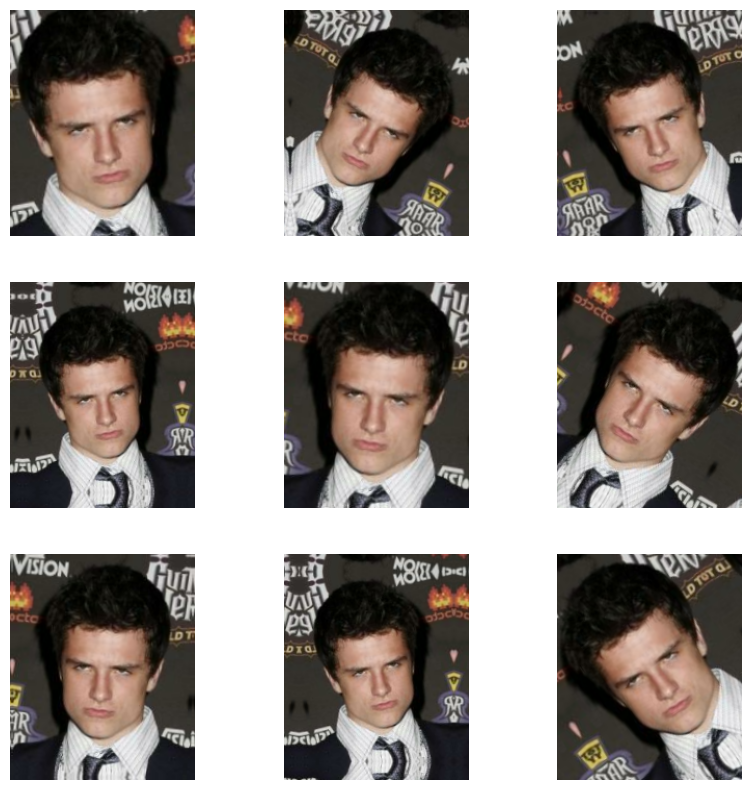

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

In [ ]:
inputs = keras.Input(shape=(218, 178, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(loss="binary_crossentropy",
optimizer="rmsprop",
metrics=["accuracy"])

In [ ]:
callbacks = [
keras.callbacks.ModelCheckpoint(
filepath="convnet_from_scratch_with_augmentation.keras",
save_best_only=True,
monitor="val_loss")
]
history = model.fit(
train_dataset,
epochs=100,
validation_data=validation_dataset,
callbacks=callbacks)

Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.5300 - loss: 0.7024 - val_accuracy: 0.5590 - val_loss: 0.6848
Epoch 2/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.6300 - loss: 0.6553 - val_accuracy: 0.6950 - val_loss: 0.5851
Epoch 3/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.6870 - loss: 0.6053 - val_accuracy: 0.7320 - val_loss: 0.5465
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.7285 - loss: 0.5632 - val_accuracy: 0.7060 - val_loss: 0.5499
Epoch 5/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.7580 - loss: 0.5096 - val_accuracy: 0.7730 - val_loss: 0.4773
Epoch 6/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.7945 - loss: 0.4659 - val_accuracy: 0.8460 - val_loss: 0.3502
Epoch 7/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8250 - loss: 0.3911 - val_accuracy: 0.8410 - val_loss: 0.3680
Epoch 8/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.8505 - loss: 0.3473 - val_accuracy: 0.

In [ ]:
model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy model from scratch(with data augmentation and dropout): {test_acc:.3f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9400 - loss: 0.1631
Test accuracy: 0.940


In [ ]:
conv_base = keras.applications.vgg16.VGG16(
weights="imagenet",
include_top=False,
input_shape=(218, 178, 3))

In [ ]:
import numpy as np
def get_features_and_labels(dataset):
  all_features = []
  all_labels = []
  for images, labels in dataset:
    preprocessed_images = keras.applications.vgg16.preprocess_input(images)
    features = conv_base.predict(preprocessed_images)
    all_features.append(features)
    all_labels.append(labels)
  return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
train_features.shape

(2000, 6, 5, 512)

In [ ]:
inputs = keras.Input(shape=(6, 5, 512))
x = layers.Flatten()(inputs)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)

In [ ]:
model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])
callbacks = [
    keras.callbacks.ModelCheckpoint(
      filepath="feature_extraction.keras",
      save_best_only=True,
      monitor="val_loss")
    ]
history = model.fit(
  train_features, train_labels,
  epochs=20,
  validation_data=(val_features, val_labels),
  callbacks=callbacks)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.8555 - loss: 11.4466 - val_accuracy: 0.8970 - val_loss: 5.2349
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9400 - loss: 3.1946 - val_accuracy: 0.8400 - val_loss: 14.9633
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9555 - loss: 1.8548 - val_accuracy: 0.9110 - val_loss: 7.5368
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9695 - loss: 1.2794 - val_accuracy: 0.8920 - val_loss: 10.9213
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9740 - loss: 1.3293 - val_accuracy: 0.9160 - val_loss: 7.3878
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9855 - loss: 0.4675 - val_accuracy: 0.8920 - val_loss: 8.8528
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9900 - loss: 0.4504 - val_accuracy: 0.9150 - val_loss: 8.6802
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9865 - loss: 0.5057 - val_accuracy: 0.9190 - val_l

In [52]:
model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = model.evaluate(x=test_features, y=test_labels)
print(f"Test accuracy (pretrained model with fast feature extraction): {test_acc:.3f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8960 - loss: 5.8689
Test accuracy (pretrained model with fast feature extraction): 0.896


In [56]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
  layer.trainable = False

In [57]:
data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
  ]
)
inputs = keras.Input(shape=(218, 178, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

In [58]:
model.compile(loss="binary_crossentropy",
              optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
              metrics=["accuracy"])
callbacks = [
  keras.callbacks.ModelCheckpoint(
  filepath="fine_tuning.keras",
  save_best_only=True,
  monitor="val_loss")
]
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 292ms/step - accuracy: 0.7175 - loss: 2.2408 - val_accuracy: 0.8660 - val_loss: 0.7700
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 223ms/step - accuracy: 0.8370 - loss: 0.9244 - val_accuracy: 0.8970 - val_loss: 0.5167
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 217ms/step - accuracy: 0.8750 - loss: 0.5264 - val_accuracy: 0.9170 - val_loss: 0.3832
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 213ms/step - accuracy: 0.8930 - loss: 0.4002 - val_accuracy: 0.9260 - val_loss: 0.3097
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 212ms/step - accuracy: 0.8905 - loss: 0.3361 - val_accuracy: 0.9250 - val_loss: 0.2891
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 212ms/step - accuracy: 0.9150 - loss: 0.2772 - val_accuracy: 0.9380 - val_loss: 0.2481
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 213ms/step - accuracy: 0.9280 - loss: 0.2172 - val_accuracy: 0.9430 - val_loss: 0.2213
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 208ms/step - accuracy: 0.9325 - loss: 0.1997 - val_accu

In [59]:
model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.9540 - loss: 0.1813
Test accuracy: 0.954
